In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df=pd.read_csv("Summary of Weather.csv",low_memory=False)

In [3]:
df.head()

,STA,Date,Precip,WindGustSpd,MaxTemp,MinTemp,MeanTemp,Snowfall,PoorWeather,YR,...,FB,FTI,ITH,PGT,TSHDSBRSGF,SD3,RHX,RHN,RVG,WTE
0,10001,1942-7-1,1.016,NaN,25.555556,22.222222,23.888889,0,NaN,42,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,10001,1942-7-2,0,NaN,28.888889,21.666667,25.555556,0,NaN,42,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,10001,1942-7-3,2.54,NaN,26.111111,22.222222,24.444444,0,NaN,42,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,10001,1942-7-4,2.54,NaN,26.666667,22.222222,24.444444,0,NaN,42,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,10001,1942-7-5,0,NaN,26.666667,21.666667,24.444444,0,NaN,42,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119040 entries, 0 to 119039
Data columns (total 31 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   STA          119040 non-null  int64  
 1   Date         119040 non-null  object 
 2   Precip       119040 non-null  object 
 3   WindGustSpd  532 non-null     float64
 4   MaxTemp      119040 non-null  float64
 5   MinTemp      119040 non-null  float64
 6   MeanTemp     119040 non-null  float64
 7   Snowfall     117877 non-null  object 
 8   PoorWeather  34237 non-null   object 
 9   YR           119040 non-null  int64  
 10  MO           119040 non-null  int64  
 11  DA           119040 non-null  int64  
 12  PRCP         117108 non-null  object 
 13  DR           533 non-null     float64
 14  SPD          532 non-null     float64
 15  MAX          118566 non-null  float64
 16  MIN          118572 non-null  float64
 17  MEA          118542 non-null  float64
 18  SNF          117877 non-

In [5]:
df.isnull().sum()

STA                 0
Date                0
Precip              0
WindGustSpd    118508
MaxTemp             0
MinTemp             0
MeanTemp            0
Snowfall         1163
PoorWeather     84803
YR                  0
MO                  0
DA                  0
PRCP             1932
DR             118507
SPD            118508
MAX               474
MIN               468
MEA               498
SNF              1163
SND            113477
FT             119040
FB             119040
FTI            119040
ITH            119040
PGT            118515
TSHDSBRSGF      84803
SD3            119040
RHX            119040
RHN            119040
RVG            119040
WTE            119040
dtype: int64

In [6]:
#precip->>yağış miktarı  maxtemp->>günlük max sıcaklık  mintemp-->günlük min sıcaklık
#meantemp->>günlük ort sıcaklık  snowfall->>kar yağışı yr->>yıl mo->>ay da->>gün ,
# prcp->>yağış miktarı  max->>max sıcaklık  min->>min sıcaklık  mea->>ort sıcaklık
#snf->>kar yağışı miktarı


In [7]:
df_drop=df.copy()

In [8]:
df_drop=df_drop.dropna(thresh=len(df_drop)*0.3,axis=1)

In [9]:
df_drop.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119040 entries, 0 to 119039
Data columns (total 15 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   STA       119040 non-null  int64  
 1   Date      119040 non-null  object 
 2   Precip    119040 non-null  object 
 3   MaxTemp   119040 non-null  float64
 4   MinTemp   119040 non-null  float64
 5   MeanTemp  119040 non-null  float64
 6   Snowfall  117877 non-null  object 
 7   YR        119040 non-null  int64  
 8   MO        119040 non-null  int64  
 9   DA        119040 non-null  int64  
 10  PRCP      117108 non-null  object 
 11  MAX       118566 non-null  float64
 12  MIN       118572 non-null  float64
 13  MEA       118542 non-null  float64
 14  SNF       117877 non-null  object 
dtypes: float64(6), int64(4), object(5)
memory usage: 13.6+ MB


In [10]:
df_drop.isnull().sum()

STA            0
Date           0
Precip         0
MaxTemp        0
MinTemp        0
MeanTemp       0
Snowfall    1163
YR             0
MO             0
DA             0
PRCP        1932
MAX          474
MIN          468
MEA          498
SNF         1163
dtype: int64

In [11]:
df_drop["Snowfall"].value_counts()

Snowfall
0          115690
5.08          534
2.54          339
7.62          330
10.16         205
12.7           92
20.32          83
17.78          78
15.24          74
22.86          69
25.4           68
#VALUE!        44
27.94          40
30.48          31
45.72          25
50.8           24
48.26          22
35.56          20
33.02          15
60.96          13
38.1           11
66.04          11
53.34          10
43.18          10
63.5            7
55.88           6
40.64           6
76.2            5
58.42           5
81.28           4
78.74           2
73.66           1
86.36           1
83.82           1
68.58           1
Name: count, dtype: int64

In [12]:
df_drop["Snowfall"]=df_drop["Snowfall"].replace("#VALUE!",np.nan)

In [13]:
df_drop["Snowfall"]=df_drop["Snowfall"].fillna(0)

In [14]:
df_drop.isnull().sum()

STA            0
Date           0
Precip         0
MaxTemp        0
MinTemp        0
MeanTemp       0
Snowfall       0
YR             0
MO             0
DA             0
PRCP        1932
MAX          474
MIN          468
MEA          498
SNF         1163
dtype: int64

In [15]:
df_drop["Snowfall"].value_counts()

Snowfall
0        115690
0          1207
5.08        534
2.54        339
7.62        330
10.16       205
12.7         92
20.32        83
17.78        78
15.24        74
22.86        69
25.4         68
27.94        40
30.48        31
45.72        25
50.8         24
48.26        22
35.56        20
33.02        15
60.96        13
38.1         11
66.04        11
43.18        10
53.34        10
63.5          7
55.88         6
40.64         6
76.2          5
58.42         5
81.28         4
78.74         2
73.66         1
86.36         1
83.82         1
68.58         1
Name: count, dtype: int64

In [16]:
df_drop["Snowfall"]=df_drop["Snowfall"].astype(float)

In [17]:
df_drop.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119040 entries, 0 to 119039
Data columns (total 15 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   STA       119040 non-null  int64  
 1   Date      119040 non-null  object 
 2   Precip    119040 non-null  object 
 3   MaxTemp   119040 non-null  float64
 4   MinTemp   119040 non-null  float64
 5   MeanTemp  119040 non-null  float64
 6   Snowfall  119040 non-null  float64
 7   YR        119040 non-null  int64  
 8   MO        119040 non-null  int64  
 9   DA        119040 non-null  int64  
 10  PRCP      117108 non-null  object 
 11  MAX       118566 non-null  float64
 12  MIN       118572 non-null  float64
 13  MEA       118542 non-null  float64
 14  SNF       117877 non-null  object 
dtypes: float64(7), int64(4), object(4)
memory usage: 13.6+ MB


In [18]:
df_drop["Precip"].value_counts()

Precip
0          64267
T          16753
0.254       3389
0.508       2909
0.762       2015
           ...  
123.698        1
106.68         1
126.492        1
123.952        1
161.036        1
Name: count, Length: 540, dtype: int64

In [19]:
df_drop["Precip"]=df_drop["Precip"].replace("T",0)

In [20]:
df_drop["Precip"]=df_drop["Precip"].astype(float)

In [21]:
df_drop.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119040 entries, 0 to 119039
Data columns (total 15 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   STA       119040 non-null  int64  
 1   Date      119040 non-null  object 
 2   Precip    119040 non-null  float64
 3   MaxTemp   119040 non-null  float64
 4   MinTemp   119040 non-null  float64
 5   MeanTemp  119040 non-null  float64
 6   Snowfall  119040 non-null  float64
 7   YR        119040 non-null  int64  
 8   MO        119040 non-null  int64  
 9   DA        119040 non-null  int64  
 10  PRCP      117108 non-null  object 
 11  MAX       118566 non-null  float64
 12  MIN       118572 non-null  float64
 13  MEA       118542 non-null  float64
 14  SNF       117877 non-null  object 
dtypes: float64(8), int64(4), object(3)
memory usage: 13.6+ MB


In [22]:
df_drop[["MAX","MaxTemp"]]

,MAX,MaxTemp
0,78.0,25.555556
1,84.0,28.888889
2,79.0,26.111111
3,80.0,26.666667
4,80.0,26.666667
...,...,...
119035,83.0,28.333333
119036,85.0,29.444444
119037,83.0,28.333333
119038,83.0,28.333333


In [23]:
df_drop["celcius"]=(df_drop["MAX"]-32)*5/9

In [24]:
df_drop[["MAX","MaxTemp","celcius"]]

,MAX,MaxTemp,celcius
0,78.0,25.555556,25.555556
1,84.0,28.888889,28.888889
2,79.0,26.111111,26.111111
3,80.0,26.666667,26.666667
4,80.0,26.666667,26.666667
...,...,...,...
119035,83.0,28.333333,28.333333
119036,85.0,29.444444,29.444444
119037,83.0,28.333333,28.333333
119038,83.0,28.333333,28.333333


In [25]:
df_drop.head()

,STA,Date,Precip,MaxTemp,MinTemp,MeanTemp,Snowfall,YR,MO,DA,PRCP,MAX,MIN,MEA,SNF,celcius
0,10001,1942-7-1,1.016,25.555556,22.222222,23.888889,0.0,42,7,1,0.04,78.0,72.0,75.0,0,25.555556
1,10001,1942-7-2,0.000,28.888889,21.666667,25.555556,0.0,42,7,2,0,84.0,71.0,78.0,0,28.888889
2,10001,1942-7-3,2.540,26.111111,22.222222,24.444444,0.0,42,7,3,0.1,79.0,72.0,76.0,0,26.111111
3,10001,1942-7-4,2.540,26.666667,22.222222,24.444444,0.0,42,7,4,0.1,80.0,72.0,76.0,0,26.666667
4,10001,1942-7-5,0.000,26.666667,21.666667,24.444444,0.0,42,7,5,0,80.0,71.0,76.0,0,26.666667


In [26]:
df_drop.columns

Index(['STA', 'Date', 'Precip', 'MaxTemp', 'MinTemp', 'MeanTemp', 'Snowfall',
       'YR', 'MO', 'DA', 'PRCP', 'MAX', 'MIN', 'MEA', 'SNF', 'celcius'],
      dtype='object')

In [27]:
df_drop.drop(["MAX","MIN","MEA","SNF","PRCP","Date","celcius"],axis=1,inplace=True)

In [28]:
df_drop.isnull().sum()

STA         0
Precip      0
MaxTemp     0
MinTemp     0
MeanTemp    0
Snowfall    0
YR          0
MO          0
DA          0
dtype: int64

In [29]:
df_drop.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119040 entries, 0 to 119039
Data columns (total 9 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   STA       119040 non-null  int64  
 1   Precip    119040 non-null  float64
 2   MaxTemp   119040 non-null  float64
 3   MinTemp   119040 non-null  float64
 4   MeanTemp  119040 non-null  float64
 5   Snowfall  119040 non-null  float64
 6   YR        119040 non-null  int64  
 7   MO        119040 non-null  int64  
 8   DA        119040 non-null  int64  
dtypes: float64(5), int64(4)
memory usage: 8.2 MB


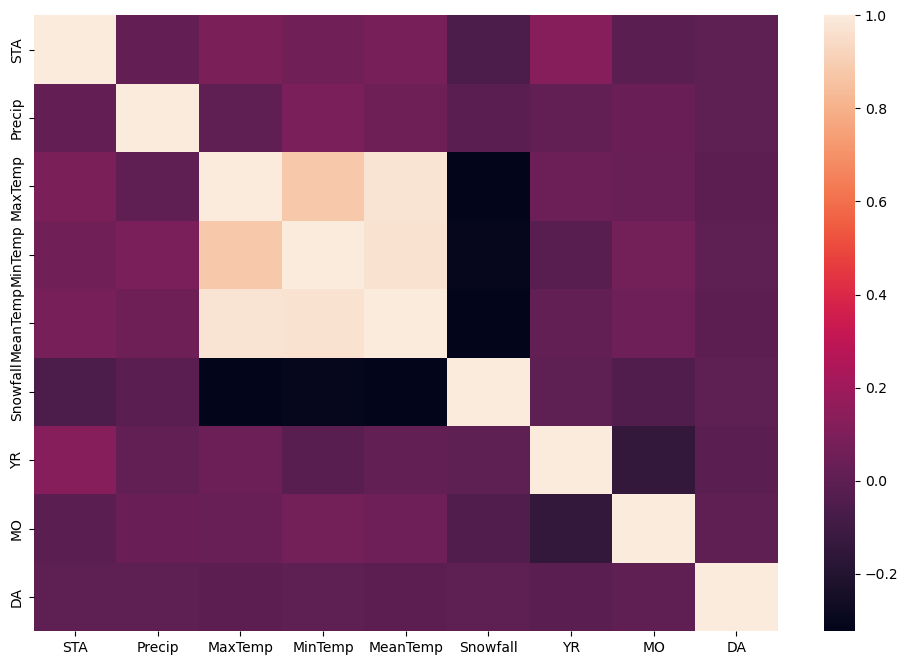

In [32]:
plt.figure(figsize=(12,8))
sns.heatmap(df_drop.corr())
plt.show()

In [64]:
from sklearn.linear_model import LassoCV,LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [65]:
x=df_drop[['MinTemp', 'MeanTemp', 'Precip', 'Snowfall']]
y=df_drop["MaxTemp"]

In [66]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.25,random_state=42)
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

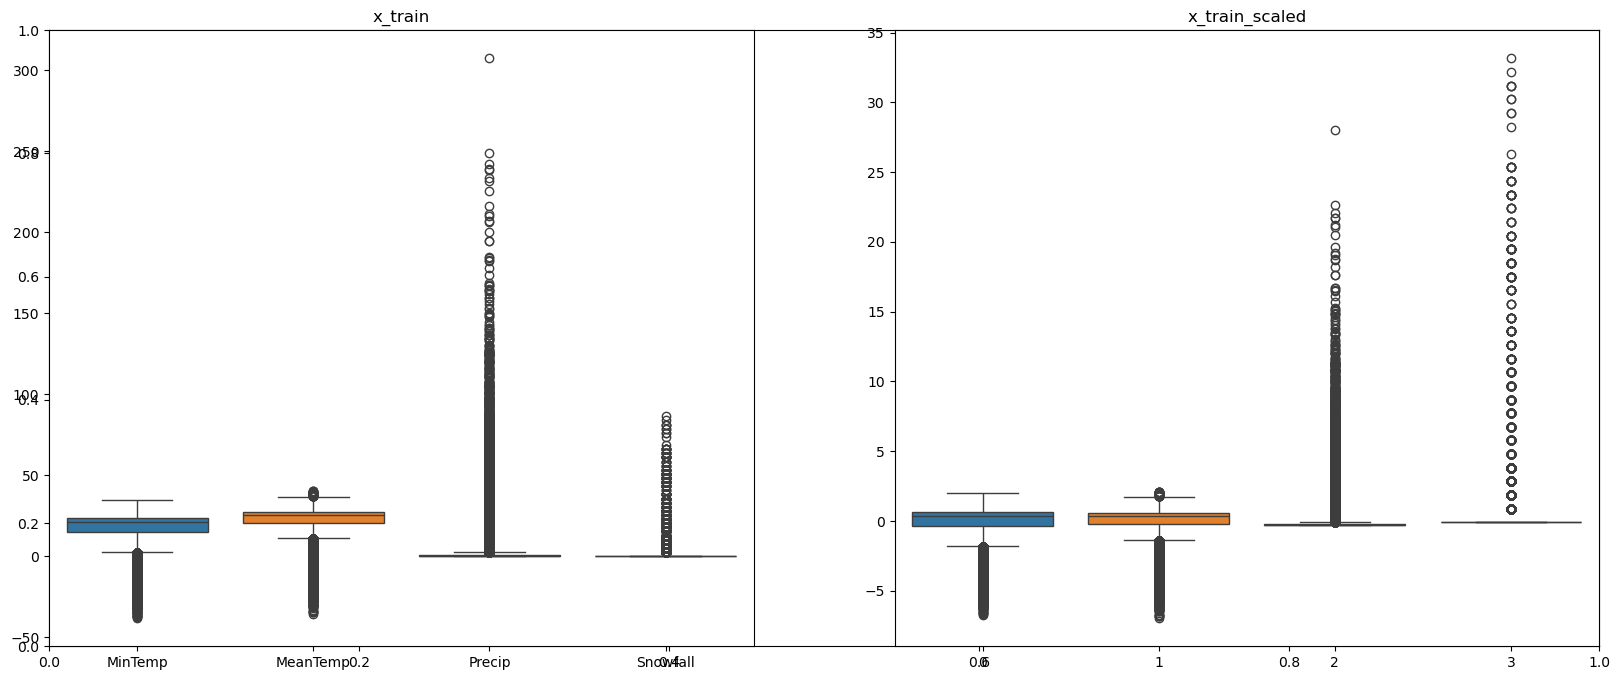

In [67]:
plt.subplots(figsize=(20,8))
plt.subplot(1,2,1)
sns.boxplot(data=x_train)
plt.title("x_train")
plt.subplot(1,2,2)
sns.boxplot(data=x_train_scaled)
plt.title("x_train_scaled")
plt.show()

mean absolute error:  0.40768587084517605
mean squared error:  0.7298411958597386
r2 score:  0.9902457792230994


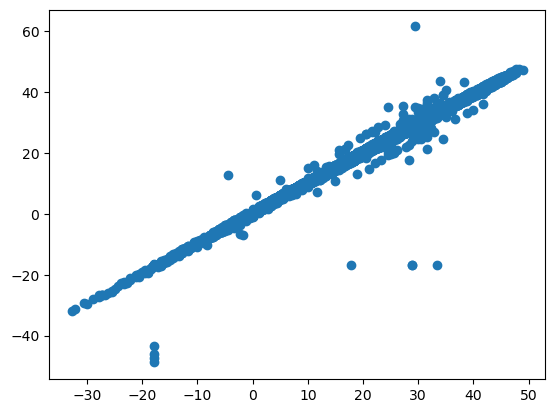

In [68]:
linear=LinearRegression()
linear.fit(x_train_scaled,y_train)
y_pred=linear.predict(x_test_scaled)
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("mean absolute error: ",mae)
print("mean squared error: ",mse)
print("r2 score: ",score)
plt.scatter(y_test,y_pred)
plt.show()

mean absolute error:  1.7596577941168936
mean squared error:  5.568196390518473
r2 score:  0.9255818700967164


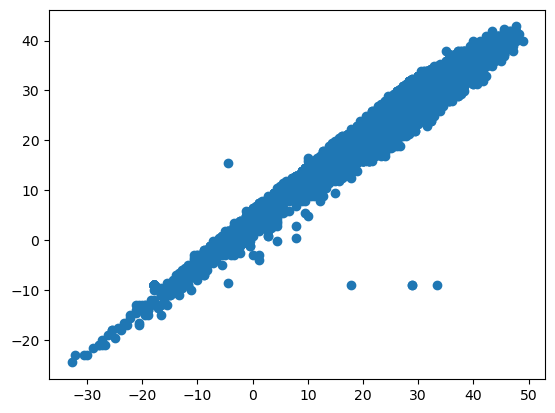

In [69]:
from sklearn.linear_model import Lasso
lasso=Lasso()
lasso.fit(x_train_scaled,y_train)
y_pred=lasso.predict(x_test_scaled)
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("mean absolute error: ",mae)
print("mean squared error: ",mse)
print("r2 score: ",score)
plt.scatter(y_test,y_pred)
plt.show()

mean absolute error:  0.43347536703919476
mean squared error:  0.748359701060339
r2 score:  0.9899982821111118


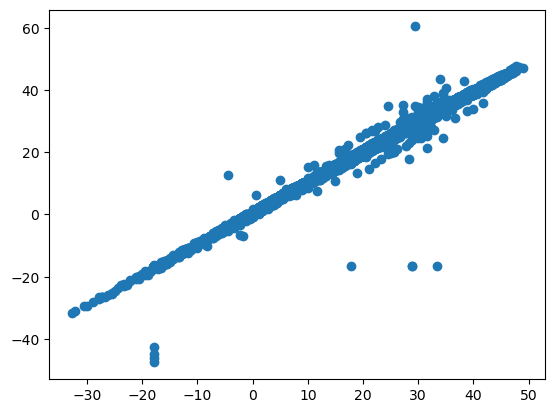

In [70]:

lassocv=LassoCV(cv=5)
lassocv.fit(x_train_scaled,y_train)
y_pred=lassocv.predict(x_test_scaled)
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("mean absolute error: ",mae)
print("mean squared error: ",mse)
print("r2 score: ",score)
plt.scatter(y_test,y_pred)
plt.show()

In [71]:
lassocv.alpha_

np.float64(0.008469653785167805)